# Atividade 01 - Introdução a Análise de Dados

- Aluno: Pedro Henrique Barbosa da Cunha
- Curso: Especialização em Engenharia e Análise de Dados
- Turma: 2026-02

### Sobre o dataset

O dataset escolhido é referente a potabilidade da água, escolhi ele por que estou trabalhando em um outro projeto onde o foco é a balneabilidade e segurança das praias e outros corpos d'água no meu estado (Alagoas).

Link do dataset no kaggle: https://www.kaggle.com/api/v1/datasets/download/natanaelferran/river-water-parameters

# Importação das bibliotecas

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import io
import zipfile
import urllib.request
print(pd.__version__)

3.1.0


# Carregamento dos dados

In [18]:
url = "https://www.kaggle.com/api/v1/datasets/download/natanaelferran/river-water-parameters"

with urllib.request.urlopen(url) as resp:
    zf = zipfile.ZipFile(io.BytesIO(resp.read()))

with zf.open("River water parameters.csv") as f:
    df = pd.read_csv(f)

print(df.shape)
print(df.columns.to_list())
df.head()

(219, 16)
['Date (DD/MM/YYYY)', 'Time (24 hrs XX:XX)', 'Sampling point', 'Ambient temperature (°C)', 'Ambient humidity', 'Sample temperature (°C)', 'pH', 'EC\n(µS/cm)', 'TDS\n(mg/L)', 'TSS\n(mL sed/L)', 'DO\n(mg/L)', 'Level (cm)', 'Turbidity (NTU)', 'Hardness\n(mg CaCO3/L)', 'Hardness classification', 'Total Cl-\n(mg Cl-/L)']


,Date (DD/MM/YYYY),Time (24 hrs XX:XX),Sampling point,Ambient temperature (°C),Ambient humidity,Sample temperature (°C),pH,EC\n(µS/cm),TDS\n(mg/L),TSS\n(mL sed/L),DO\n(mg/L),Level (cm),Turbidity (NTU),Hardness\n(mg CaCO3/L),Hardness classification,Total Cl-\n(mg Cl-/L)
0,09/05/2023,14:15,Puente Bilbao,17.0,0.47,19.0,8.3,1630,810,1.8,4.30,NaN,NaN,147.0,BLANDA,156.0
1,14/06/2023,14:30,Puente Bilbao,11.9,0.47,13.0,8.1,1000,490,18.0,5.30,NaN,41.2,94.0,BLANDA,78.0
2,14/06/2023,14:30,Puente Bilbao,11.9,0.47,13.0,8.2,1000,490,18.0,4.67,NaN,38.9,86.0,BLANDA,82.0
3,14/06/2023,15:00,Arroyo_Las Torres,11.9,0.47,13.0,8.3,1350,670,0.1,7.01,NaN,30.7,200.0,SEMIDURA,117.0
4,14/06/2023,15:00,Arroyo_Las Torres,11.9,0.47,13.0,8.5,1350,660,0.1,7.23,NaN,25.6,196.0,SEMIDURA,117.0


### Dicionário de dados

Parâmetros físico-químicos de um rio poluído de Buenos Aires (Argentina), medidos
em laboratório seguindo os Standard Methods. Fonte: Kaggle
(natanaelferran/river-water-parameters). Dimensão: 219 linhas × 16 colunas.

| # | Coluna original | Coluna renomeada | Tipo | Unidade | Descrição |
|---|---|---|---|---|---|
| 1 | `Date (DD/MM/YYYY)` | `date` | data | — | Data da coleta da amostra, no formato dia/mês/ano. |
| 2 | `Time (24 hrs XX:XX)` | `time` | hora | — | Hora da coleta, formato 24 h (HH:MM). |
| 3 | `Sampling point` | `sampling_point` | categórico | — | Identificação do ponto de coleta no rio. |
| 4 | `Ambient temperature (°C)` | `ambient_temp_c` | numérico | °C | Temperatura do ar no momento da coleta. |
| 5 | `Ambient humidity` | `ambient_humidity` | numérico | não informada | Umidade relativa do ar no momento da coleta.|
| 6 | `Sample temperature (°C)` | `sample_temp_c` | numérico | °C | Temperatura da água da amostra. |
| 7 | `pH` | `ph` | numérico | — | Potencial hidrogeniônico (0–14); indica acidez ou alcalinidade da água. |
| 8 | `EC\n(µS/cm)` | `ec_us_cm` | numérico | µS/cm | Condutividade elétrica; aumenta com a quantidade de íons dissolvidos. |
| 9 | `TDS\n(mg/L)` | `tds_mg_l` | numérico | mg/L | Sólidos dissolvidos totais. |
| 10 | `TSS\n(mL sed/L)` | `tss_ml_sed_l` | numérico | mL sed/L | Sólidos medidos em volume de sedimento por litro. Pela unidade, corresponde a sólidos sedimentáveis (cone Imhoff), e não a sólidos suspensos totais em mg/L. |
| 11 | `DO\n(mg/L)` | `do_mg_l` | numérico | mg/L | Oxigênio dissolvido; valores baixos indicam degradação da qualidade da água. |
| 12 | `Level (cm)` | `level_cm` | numérico | cm | Nível do rio no ponto e momento da coleta. |
| 13 | `Turbidity (NTU)` | `turbidity_ntu` | numérico | NTU | Turbidez; quanto maior, mais turva a água. |
| 14 | `Hardness\n(mg CaCO3/L)` | `hardness_mg_caco3_l` | numérico | mg CaCO₃/L | Dureza total, expressa como carbonato de cálcio equivalente. |
| 15 | `Hardness classification` | `hardness_class` | categórico | — | Classificação da água pela dureza (ex.: branda, moderada, dura). |
| 16 | `Total Cl-\n(mg Cl-/L)` | `total_chloride_mg_l` | numérico | mg Cl⁻/L | Concentração total de cloretos. |


# Renomeando as colunas

In [19]:
COLUMN_MAP = {
    "Date (DD/MM/YYYY)": "date",
    "Time (24 hrs XX:XX)": "time",
    "Sampling point": "sampling_point",
    "Ambient temperature (°C)": "ambient_temp_c",
    "Ambient humidity": "ambient_humidity",
    "Sample temperature (°C)": "sample_temp_c",
    "pH": "ph",
    "EC\n(µS/cm)": "ec_us_cm",
    "TDS\n(mg/L)": "tds_mg_l",
    "TSS\n(mL sed/L)": "tss_ml_sed_l",
    "DO\n(mg/L)": "do_mg_l",
    "Level (cm)": "level_cm",
    "Turbidity (NTU)": "turbidity_ntu",
    "Hardness\n(mg CaCO3/L)": "hardness_mg_caco3_l",
    "Hardness classification": "hardness_class",
    "Total Cl-\n(mg Cl-/L)": "total_chloride_mg_l",
}

df = df.rename(columns=COLUMN_MAP)
df.head(5)

,date,time,sampling_point,ambient_temp_c,ambient_humidity,sample_temp_c,ph,ec_us_cm,tds_mg_l,tss_ml_sed_l,do_mg_l,level_cm,turbidity_ntu,hardness_mg_caco3_l,hardness_class,total_chloride_mg_l
0,09/05/2023,14:15,Puente Bilbao,17.0,0.47,19.0,8.3,1630,810,1.8,4.30,NaN,NaN,147.0,BLANDA,156.0
1,14/06/2023,14:30,Puente Bilbao,11.9,0.47,13.0,8.1,1000,490,18.0,5.30,NaN,41.2,94.0,BLANDA,78.0
2,14/06/2023,14:30,Puente Bilbao,11.9,0.47,13.0,8.2,1000,490,18.0,4.67,NaN,38.9,86.0,BLANDA,82.0
3,14/06/2023,15:00,Arroyo_Las Torres,11.9,0.47,13.0,8.3,1350,670,0.1,7.01,NaN,30.7,200.0,SEMIDURA,117.0
4,14/06/2023,15:00,Arroyo_Las Torres,11.9,0.47,13.0,8.5,1350,660,0.1,7.23,NaN,25.6,196.0,SEMIDURA,117.0


# Visão inicial dos dados (info e describe)

In [20]:
print(df.info())
print()
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 219 entries, 0 to 218
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 219 non-null    str    
 1   time                 219 non-null    str    
 2   sampling_point       219 non-null    str    
 3   ambient_temp_c       219 non-null    float64
 4   ambient_humidity     219 non-null    float64
 5   sample_temp_c        219 non-null    float64
 6   ph                   219 non-null    float64
 7   ec_us_cm             219 non-null    int64  
 8   tds_mg_l             219 non-null    int64  
 9   tss_ml_sed_l         213 non-null    float64
 10  do_mg_l              219 non-null    float64
 11  level_cm             180 non-null    float64
 12  turbidity_ntu        218 non-null    float64
 13  hardness_mg_caco3_l  217 non-null    float64
 14  hardness_class       217 non-null    str    
 15  total_chloride_mg_l  213 non-null    float64
dtypes

### Insights a partir das estatísticas

- **Período e volume**: são 219 amostras coletadas entre maio e novembro de 2023, em 5 pontos do rio.
- **Valores ausentes**: a maioria das colunas está completa; `level_cm` é a que mais tem faltantes (39 nulos), seguida de `tss_ml_sed_l` e `total_chloride_mg_l` (6 nulos cada).
- **pH**: varia de 7,2 a 8,7, com média de 8,03. A água é levemente alcalina e bem estável (desvio padrão de apenas 0,29).
- **Oxigênio dissolvido (DO)**: média de apenas 2,62 mg/L, mediana de 1,87 mg/L e mínimo de 0 mg/L. O máximo é 9,12 mg/L. Em geral, valores abaixo de 5 mg/L já indicam água de má qualidade para a vida aquática, o que confirma que o rio é bastante poluído.
- **Turbidez**: média de 145 NTU, mas mediana de apenas 59 NTU, com máximo de 1000 NTU (provavelmente o limite do aparelho). A diferença entre média e mediana mostra que existem alguns valores extremos puxando a média para cima.
- **Sólidos sedimentáveis (TSS)**: mesma situação da turbidez: média de 61, mediana de 48 e máximo de 650 mL/L.
- **Condutividade (EC) e TDS**: médias de 1265 µS/cm e 624 mg/L. O TDS fica perto da metade da EC em todas as faixas, o que é esperado, já que as duas medidas dependem dos sais dissolvidos.
- **Temperatura**: a água (média de 19,6 °C) costuma estar um pouco mais quente que o ar (média de 17,6 °C).
- **Dureza**: varia de 86 a 316 mg CaCO₃/L, com média de 190,7.

# Variáveis categóricas (value_counts e unique)

In [21]:
print(df['sampling_point'].unique())
print()
print(df['hardness_class'].unique())

<StringArray>
[    'Puente Bilbao', 'Arroyo_Las Torres',   'Puente Irigoyen',
      'Puente Falbo',   'Arroyo Salguero']
Length: 5, dtype: str

<StringArray>
['BLANDA', 'SEMIDURA', nan]
Length: 3, dtype: str


In [22]:
print(df['hardness_class'].value_counts(dropna=False))

hardness_class
SEMIDURA    155
BLANDA       62
NaN           2
Name: count, dtype: int64


sampling_point
Puente Bilbao        45
Arroyo_Las Torres    44
Puente Irigoyen      44
Puente Falbo         44
Arroyo Salguero      42
Name: count, dtype: int64


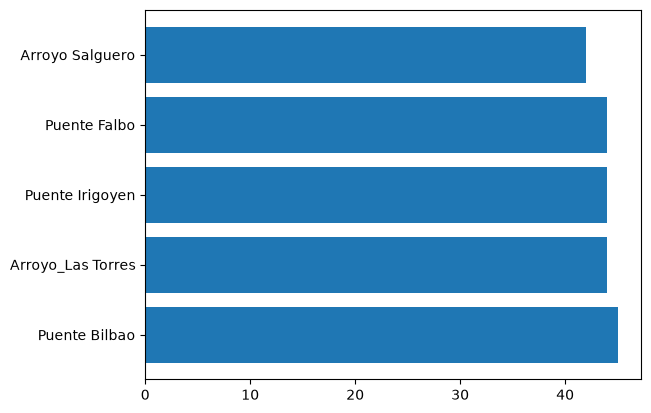

In [23]:
# Visualizando a quantidade de coleta em cada ponto de coleta.

df_sampling_point = df['sampling_point'].value_counts()
print(df_sampling_point)
plot = plt.barh(y=df_sampling_point.index, width=df_sampling_point)

- Existem **5 pontos de coleta**, e cada um tem entre 42 e 45 amostras, então os dados estão bem distribuídos entre os pontos.
- A coluna `hardness_class` tem só duas categorias: **SEMIDURA** (155 amostras) e **BLANDA** (62 amostras), além de 2 valores nulos. Os nomes estão em espanhol: *blanda* = branda e *semidura* = semidura.

# Análises com groupby e sort_values

In [24]:
# Média dos principais parâmetros por ponto de coleta, ordenado pelo oxigênio dissolvido
cols = ['ph', 'do_mg_l', 'ec_us_cm', 'turbidity_ntu', 'hardness_mg_caco3_l', 'total_chloride_mg_l']
df_por_ponto = df.groupby('sampling_point')[cols].mean().round(2).sort_values('do_mg_l')
df_por_ponto

,ph,do_mg_l,ec_us_cm,turbidity_ntu,hardness_mg_caco3_l,total_chloride_mg_l
sampling_point,,,,,,
Puente Falbo,7.96,1.51,1377.27,117.41,189.77,114.79
Puente Irigoyen,8.06,1.85,1340.68,80.88,176.84,116.41
Puente Bilbao,7.93,2.41,1301.33,373.59,141.74,104.93
Arroyo Salguero,7.98,3.39,955.00,13.68,237.67,58.38
Arroyo_Las Torres,8.22,3.99,1333.64,133.24,208.57,117.34


In [25]:
# Classificação de dureza em cada ponto de coleta
df.groupby('sampling_point')['hardness_class'].value_counts().sort_values(ascending=False)

sampling_point     hardness_class
Arroyo Salguero    SEMIDURA          40
Arroyo_Las Torres  SEMIDURA          38
Puente Falbo       SEMIDURA          31
Puente Irigoyen    SEMIDURA          29
Puente Bilbao      BLANDA            26
                   SEMIDURA          17
Puente Irigoyen    BLANDA            15
Puente Falbo       BLANDA            13
Arroyo_Las Torres  BLANDA             6
Arroyo Salguero    BLANDA             2
Name: count, dtype: int64

In [26]:
# Média de temperatura da água e oxigênio dissolvido por mês
df['month'] = pd.to_datetime(df['date'], dayfirst=True).dt.month
df_por_mes = df.groupby('month')[['sample_temp_c', 'do_mg_l']].mean().round(2)
df_por_mes

,sample_temp_c,do_mg_l
month,,
5,19.00,4.30
6,14.84,4.17
7,20.43,3.20
8,17.98,2.72
9,18.69,3.75
10,21.15,1.39
11,26.09,0.97


In [27]:
# As 5 amostras com maior turbidez
df.sort_values('turbidity_ntu', ascending=False)[['date', 'sampling_point', 'turbidity_ntu', 'tss_ml_sed_l']].head(5)

,date,sampling_point,turbidity_ntu,tss_ml_sed_l
60,02/08/2023,Puente Bilbao,1000.0,650.0
79,15/08/2023,Puente Bilbao,1000.0,620.0
80,15/08/2023,Puente Bilbao,1000.0,620.0
89,18/08/2023,Puente Bilbao,1000.0,82.0
40,05/07/2023,Puente Bilbao,1000.0,92.0


- **Puente Falbo** tem a pior média de oxigênio dissolvido (1,51 mg/L), seguida de Puente Irigoyen (1,85 mg/L). **Arroyo_Las Torres** tem a melhor média (3,99 mg/L), mas mesmo assim fica abaixo de 5 mg/L.
- **Arroyo Salguero** se destaca por ter a menor condutividade (955 µS/cm), a menor turbidez (13,7 NTU) e o menor teor de cloretos (58,4 mg/L). Por outro lado, tem a maior dureza média (237,7).
- **Puente Bilbao** tem uma turbidez média bem acima dos outros pontos (373,6 NTU), e todas as 5 maiores turbidezes (1000 NTU) foram medidas lá. É também o único ponto em que a classificação BLANDA aparece mais vezes que a SEMIDURA.
- **Por mês**: o oxigênio dissolvido cai de ~4,2 mg/L em junho para ~1,0 mg/L em novembro, enquanto a temperatura da água sobe de ~14,8 °C para ~26,1 °C. Isso faz sentido, porque água mais quente consegue reter menos oxigênio.

#  Gráfico com Matplotlib

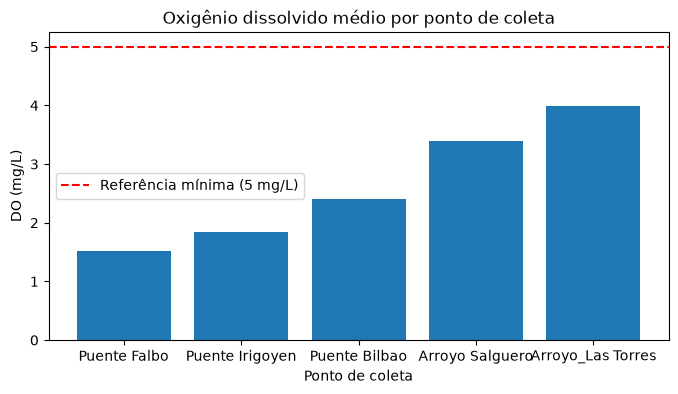

In [28]:
pontos = df_por_ponto.index.values
oxigenio = df_por_ponto['do_mg_l'].values

plt.figure(figsize=(8, 4))
plt.bar(pontos, oxigenio)
plt.axhline(5, color='red', linestyle='--', label='Referência mínima (5 mg/L)')
plt.title('Oxigênio dissolvido médio por ponto de coleta')
plt.xlabel('Ponto de coleta')
plt.ylabel('DO (mg/L)')
plt.legend()
plt.show()

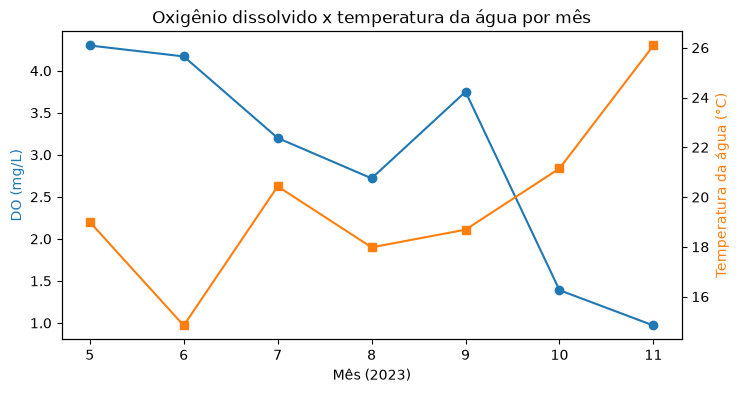

In [29]:
meses = df_por_mes.index.values
temp_agua = df_por_mes['sample_temp_c'].values
oxigenio_mes = df_por_mes['do_mg_l'].values

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(meses, oxigenio_mes, marker='o', color='tab:blue', label='DO (mg/L)')
ax1.set_xlabel('Mês (2023)')
ax1.set_ylabel('DO (mg/L)', color='tab:blue')

ax2 = ax1.twinx()
ax2.plot(meses, temp_agua, marker='s', color='tab:orange', label='Temp. da água (°C)')
ax2.set_ylabel('Temperatura da água (°C)', color='tab:orange')

plt.title('Oxigênio dissolvido x temperatura da água por mês')
plt.show()

# Conclusão

Os dados mostram que o rio está bastante poluído. 

O oxigênio dissolvido tem média de apenas 2,6 mg/L, e cerca de 85% das amostras ficaram abaixo de 5 mg/L, que é a referência mínima para a vida aquática. 

O pH ficou estável e levemente alcalino (por volta de 8) durante todo o período. 

Comparando os pontos de coleta, Puente Falbo e Puente Irigoyen tiveram os níveis de oxigênio mais baixos, Puente Bilbao teve a maior turbidez (com vários registros no limite de 1000 NTU), e Arroyo Salguero teve a água menos turva, com menos sais e menos cloretos. 

Ao longo dos meses, o oxigênio dissolvido caiu conforme a temperatura da água aumentou, chegando a cerca de 1 mg/L em novembro. Isso indica que, nos meses mais quentes, a situação do rio piora. 